# Pillar 3 — Competition and entry windows

Scores every U.S. metro on **how hard it is to win deposit share**, and whether there is an opening. Edit weights here, build metrics, score, inspect BankUnited markets, run diagnostics, and export CSV.

**How to use**
1. Edit **`WEIGHTS`** (and settings) in section 2, then *Run All*. Weights don't have to sum to 100%; they're rescaled.
2. Section 3 documents every metric.
3. Sections 6–8 show scores, BankUnited markets, a Charlotte breakdown, and diagnostics.

**Data:** `data/processed/` (`msa_year`, `bank_msa_year`). Nothing is downloaded. Metric formulas are built via `src/pillar3_competition.py`; **weights and scoring live in this notebook**.

**Output:** `outputs/pillar_scores/pillar3_scores.csv` and `pillar3_run.json`.


## 1. Setup


In [2]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "msa_year.parquet").exists() and (p / "src" / "pillar3_competition.py").exists():
            return p
        sibling = p / "bankunited-market-expansion"
        if (sibling / "data" / "processed" / "msa_year.parquet").exists():
            return sibling
    raise FileNotFoundError(
        "Need bankunited-market-expansion with data/processed/msa_year.parquet and src/pillar3_competition.py."
    )


ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))
from src import pillar3_competition as p3

PROCESSED = ROOT / "data" / "processed"
REFERENCE = ROOT / "data" / "reference"
msa_year = pd.read_parquet(PROCESSED / "msa_year.parquet")
bank_msa_year = pd.read_parquet(PROCESSED / "bank_msa_year.parquet")

print(f"repo: {ROOT.name}")
print(f"msa_year {msa_year.shape}, bank_msa_year {bank_msa_year.shape}")


repo: bankunited-market-expansion
msa_year (3930, 56), bank_msa_year (331879, 21)


In [3]:
def r12(s):
    return s.astype(float).round(12)


def oriented_percentiles(metrics, directions):
    """Average-rank percentiles (0-100) among MSAs that have the metric; higher always = more attractive."""
    P = pd.DataFrame(index=metrics.index)
    for col in metrics.columns:
        v = metrics[col] if directions[col] == "Higher" else -metrics[col]
        n = v.notna().sum()
        P[col] = 100 * (v.rank(method="average") - 1) / (n - 1) if n > 1 else np.nan
    return P


def score(metrics, directions, weights):
    """Available-data score and complete score. Ranks among complete MSAs only."""
    w = pd.Series(weights, dtype=float)[list(metrics.columns)]
    P = oriented_percentiles(metrics, directions)
    have = P.notna()
    avail_w = have.mul(w, axis=1).sum(axis=1)
    available = P.fillna(0).mul(w, axis=1).sum(axis=1) / avail_w.where(avail_w > 0)
    complete = available.where(have.all(axis=1))
    out = pd.DataFrame({
        "msa": pd.Series(TITLE),
        "complete_score": complete,
        "rank": complete.rank(ascending=False, method="min"),
        "available_score": available,
        "valid_metrics": have.sum(axis=1),
        "weight_coverage": avail_w,
        "missing_metrics": have.apply(lambda r: ", ".join(c for c in r.index if not r[c]), axis=1),
    })
    contrib = P.mul(w, axis=1)
    return out, P, contrib


def weight_rank_ranges(metrics, directions, weights, shock=0.25):
    """Best and worst complete rank when each weight alone moves +/- shock."""
    base, _, _ = score(metrics, directions, weights)
    ranks = [base["rank"]]
    for k in weights:
        for s in (-shock, shock):
            w = dict(weights)
            w[k] = weights[k] * (1 + s)
            tot = sum(w.values())
            w = {kk: vv / tot for kk, vv in w.items()}
            ranks.append(score(metrics, directions, w)[0]["rank"])
    R = pd.concat(ranks, axis=1)
    return pd.DataFrame({"best_rank": R.min(axis=1), "worst_rank": R.max(axis=1)})


def check_weights(weights, registry):
    w = pd.Series(weights, dtype=float)
    unknown = sorted(set(w.index) - set(registry.index))
    assert not unknown, f"weights for unknown metrics: {unknown}"
    assert (w >= 0).all(), "weights must be zero or positive"
    unavailable = [k for k in w.index if registry.loc[k, "status"] == "not available" and w[k] > 0]
    used = w[[k for k in w.index if registry.loc[k, "status"] != "not available" and w[k] > 0]]
    assert len(used) > 0, "no weighted metric is available"
    eff = used / used.sum()
    if abs(w.sum() - 1) > 1e-9:
        print(f"Note: entered weights sum to {w.sum():.4f}; they are rescaled to 100%.")
    if unavailable:
        print("Weighted but NOT available, so left out and the rest rescaled:", ", ".join(unavailable))
    return eff


def show_rank_table(results, n=25):
    cols = ["msa", "complete_score", "rank", "available_score", "valid_metrics"]
    return results.sort_values(["complete_score", "available_score"], ascending=False)[cols].head(n).round(2)


## 2. Weights and settings — edit here

Baseline = equal weight on all five  metrics. Direction is **Lower** = more attractive for an entrant (less competition → higher percentile after orientation). Charlotte is validation only — do not fit weights to Charlotte.


In [4]:
WEIGHTS = {
    # Concentration
    "deposit_hhi":             1 / 5,   # P3-01
    "top3_share":              1 / 5,   # P3-02
    # Market thinness
    "competitors_per_billion": 1 / 5,   # P3-03
    "branches_per_billion":    1 / 5,   # P3-04
    # Opening
    "leader_share_change":     1 / 5,   # P3-07
}

SETTINGS = {
    "score_year": 2024,
    "hq_adjusted": True,   # exclude main-office + home-banking bookings
}
EXAMPLE_CBSA = "16740"   # Charlotte
PILLAR_TAG = "pillar3"

universe = (
    msa_year.loc[msa_year.year == SETTINGS["score_year"], ["cbsa_code", "cbsa_title"]]
    .drop_duplicates()
    .sort_values("cbsa_code")
    .set_index("cbsa_code")
)
CBSAS = list(universe.index)
TITLE = universe.cbsa_title.to_dict()
N_MSA = len(CBSAS)
print(f"universe: {N_MSA} MSAs in {SETTINGS['score_year']}")
print("edit WEIGHTS above, then Run All to rescore")


universe: 393 MSAs in 2024
edit WEIGHTS above, then Run All to rescore


## 3. Metric dictionary

| # | Metric | Group | Definition | Why it matters | Status |
|---|---|---|---|---|---|
| 1 | Deposit HHI | Concentration | HHI of deposit shares across holding companies (0–10,000), HQ-adjusted | Contestable markets are easier to enter. | Available |
| 2 | Top-3 share | Concentration | Combined deposit share of the three largest holding companies | High concentration means leaders control the pool. | Available |
| 3 | Competitors per $1B | Market thinness | Holding companies with deposits per $1B of local deposits | Fewer incumbents per dollar = thinner competitive set. | Available |
| 4 | Branches per $1B | Market thinness | Full-service branches per $1B of local deposits | Branch density raises the cost of winning share. | Available |
| 5 | Leader share change | Opening | 3-year change in deposit share of the metro's top 3 fixed at t−3 | Falling leader share signals an opening. | Available |

P3-05 peer-set deposit share is **not used**.


In [5]:
REGISTRY = pd.DataFrame([
    ("deposit_hhi", "Deposit HHI across holding companies", "Concentration", "Lower", "June 2024",
     "bank_msa_year SOD", "available", "P3-01"),
    ("top3_share", "Top-3 holding-company deposit share", "Concentration", "Lower", "June 2024",
     "bank_msa_year SOD", "available", "P3-02"),
    ("competitors_per_billion", "Competitors per $1B of local deposits", "Market thinness", "Lower", "June 2024",
     "bank_msa_year SOD", "available", "P3-03"),
    ("branches_per_billion", "Full-service branches per $1B of local deposits", "Market thinness", "Lower", "June 2024",
     "bank_msa_year SOD", "available", "P3-04"),
    ("leader_share_change", "3-year change in leaders' deposit share", "Opening", "Lower", "2021→2024",
     "bank_msa_year SOD", "available", "P3-07"),
], columns=["key", "label", "group", "direction", "period", "source", "status", "metric_id"]).set_index("key")

EFFECTIVE = check_weights(WEIGHTS, REGISTRY)
ACTIVE = list(EFFECTIVE.index)
DIRECTIONS = REGISTRY.direction.to_dict()
METRIC_ID = REGISTRY.metric_id.to_dict()
REGISTRY["entered_weight"] = pd.Series(WEIGHTS)
REGISTRY["effective_weight"] = EFFECTIVE
REGISTRY.assign(
    entered_weight=REGISTRY.entered_weight.map("{:.1%}".format),
    effective_weight=REGISTRY.effective_weight.map(lambda v: "—" if pd.isna(v) else f"{v:.1%}"),
)


,label,group,direction,period,source,status,metric_id,entered_weight,effective_weight
key,,,,,,,,,
deposit_hhi,Deposit HHI across holding companies,Concentration,Lower,June 2024,bank_msa_year SOD,available,P3-01,20.0%,20.0%
top3_share,Top-3 holding-company deposit share,Concentration,Lower,June 2024,bank_msa_year SOD,available,P3-02,20.0%,20.0%
competitors_per_billion,Competitors per $1B of local deposits,Market thinness,Lower,June 2024,bank_msa_year SOD,available,P3-03,20.0%,20.0%
branches_per_billion,Full-service branches per $1B of local deposits,Market thinness,Lower,June 2024,bank_msa_year SOD,available,P3-04,20.0%,20.0%
leader_share_change,3-year change in leaders' deposit share,Opening,Lower,2021→2024,bank_msa_year SOD,available,P3-07,20.0%,20.0%


## 4. Data availability check


In [6]:
NEEDED = {
    "msa_year": ["cbsa_code", "cbsa_title", "year"],
    "bank_msa_year": [
        "sod_deposits_usd", "sod_main_office_deposits_usd", "sod_home_banking_office_deposits_usd",
        "sod_top_holder_rssd_id", "sod_branches_count",
    ],
}
tables_raw = {"msa_year": msa_year, "bank_msa_year": bank_msa_year}
rows = [(t, c, c in tables_raw[t].columns) for t, cols in NEEDED.items() for c in cols]
avail = pd.DataFrame(rows, columns=["table", "column", "present"])
assert avail.present.all(), avail[~avail.present]

sod_years = set(bank_msa_year.dropna(subset=["sod_deposits_usd"]).year)
checks = {
    f"SOD {SETTINGS['score_year']}": SETTINGS["score_year"] in sod_years,
    f"SOD {SETTINGS['score_year'] - 3} (for P3-07)": (SETTINGS["score_year"] - 3) in sod_years,
}
assert all(checks.values()), checks
print("All required columns and periods present:", ", ".join(checks))


All required columns and periods present: SOD 2024, SOD 2021 (for P3-07)


## 5. Build the metrics

SOD competition metrics (HQ-adjusted by default). Competitors = top holding companies. Built with `src/pillar3_competition.compute_all`, then scored in this notebook.


In [7]:
tables = {"msa_year": msa_year, "bank_msa_year": bank_msa_year}
long = p3.compute_all(tables, hq_adjusted=SETTINGS["hq_adjusted"])
wide = p3.to_wide(long)
snap = wide[wide["year"] == SETTINGS["score_year"]].set_index("cbsa_code").reindex(CBSAS)

metrics = pd.DataFrame({key: snap[METRIC_ID[key]] for key in REGISTRY.index}, index=CBSAS)

coverage = pd.DataFrame({
    "label": REGISTRY.label,
    "status": REGISTRY.status,
    "MSAs with a value": metrics.notna().sum(),
    "median": metrics.median(numeric_only=True),
})
coverage


,label,status,MSAs with a value,median
deposit_hhi,Deposit HHI across holding companies,available,393,"1,455.4944"
top3_share,Top-3 holding-company deposit share,available,393,0.5628
competitors_per_billion,Competitors per $1B of local deposits,available,393,2.9972
branches_per_billion,Full-service branches per $1B of local deposits,available,393,10.0429
leader_share_change,3-year change in leaders' deposit share,available,388,-0.0282


In [8]:
FMT_PCT = lambda v: "—" if pd.isna(v) else f"{v:.2%}"
FMT_HHI = lambda v: "—" if pd.isna(v) else f"{v:,.0f}"
FMT_NUM = lambda v: "—" if pd.isna(v) else f"{v:,.2f}"
FORMAT = {
    "deposit_hhi": FMT_HHI,
    "top3_share": FMT_PCT,
    "competitors_per_billion": FMT_NUM,
    "branches_per_billion": FMT_NUM,
    "leader_share_change": FMT_PCT,
}
metrics.join(pd.Series(TITLE, name="msa")).set_index("msa", append=True).loc[:, ACTIVE].head(10)


,,deposit_hhi,top3_share,competitors_per_billion,branches_per_billion,leader_share_change
,msa,,,,,
10180,"Abilene, TX","1,999.3869",0.6248,6.6177,15.3252,0.0260
10380,"Aguadilla, PR","5,404.8902",1.0000,1.3366,5.7920,0.0000
10420,"Akron, OH","1,460.7044",0.5658,1.3833,8.6318,-0.0243
10500,"Albany, GA","1,433.1528",0.5589,5.9422,13.1578,0.0154
10540,"Albany, OR","1,465.0745",0.5316,6.5181,14.4848,-0.0216
10580,"Albany-Schenectady-Troy, NY","1,484.1538",0.5508,0.8369,9.5330,-0.0351
10740,"Albuquerque, NM","1,699.2179",0.6378,1.2211,6.9705,-0.1401
10780,"Alexandria, LA","1,411.4343",0.5512,5.8576,23.0119,-0.0041
10900,"Allentown-Bethlehem-Easton, PA-NJ",929.1140,0.4331,1.6067,9.3892,-0.0443


## 6. Score

Each metric becomes a percentile (0–100), oriented so **higher = more attractive for an entrant** (lower competition). The **complete score** needs every weighted metric. The **available-data score** renormalizes over metrics an MSA has. Ranks are among complete MSAs only.


In [9]:
results, P, contrib = score(metrics[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict())
n_complete = int(results["rank"].notna().sum())
print(f"{n_complete} complete, {N_MSA - n_complete} partial")
print(results.loc[results["rank"].isna(), "missing_metrics"].value_counts().head(5).to_string())


388 complete, 5 partial
missing_metrics
leader_share_change    5


In [10]:
show_rank_table(results, n=25)


,msa,complete_score,rank,available_score,valid_metrics
35840,"North Port-Bradenton-Sarasota, FL",85.5200,1.0000,85.5200,5
34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",84.3700,2.0000,84.3700,5
37980,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",83.5000,3.0000,83.5000,5
33700,"Modesto, CA",81.9700,4.0000,81.9700,5
26900,"Indianapolis-Carmel-Greenwood, IN",81.6900,5.0000,81.6900,5
38860,"Portland-South Portland, ME",81.5900,6.0000,81.5900,5
28880,"Kiryas Joel-Poughkeepsie-Newburgh, NY",80.3000,7.0000,80.3000,5
34820,"Myrtle Beach-Conway-North Myrtle Beach, SC",79.9500,8.0000,79.9500,5
34940,"Naples-Marco Island, FL",79.8200,9.0000,79.8200,5
45300,"Tampa-St. Petersburg-Clearwater, FL",79.7500,10.0000,79.7500,5


## 7. BankUnited's markets and an example MSA


In [11]:
bu_branch = msa_year[
    (msa_year.year == SETTINGS["score_year"]) & (msa_year.bankunited_sod_offices_count > 0)
].cbsa_code.tolist()
BU_OFFICE_ONLY = {
    "12060": "Atlanta office",
    "16740": "Charlotte (entered Jul 2025)",
    "26420": "Houston office",
}
bu_markets = pd.DataFrame({"cbsa_code": bu_branch + [c for c in BU_OFFICE_ONLY if c not in bu_branch]})
bu_markets["presence"] = ["SOD branch" if c in bu_branch else BU_OFFICE_ONLY[c] for c in bu_markets.cbsa_code]
bu_markets = bu_markets.set_index("cbsa_code").join(
    results[["msa", "complete_score", "rank", "available_score"]]
)
bu_markets.sort_values("rank").round(2)


,presence,msa,complete_score,rank,available_score
cbsa_code,,,,,
35840,SOD branch,"North Port-Bradenton-Sarasota, FL",85.5200,1.0000,85.5200
34940,SOD branch,"Naples-Marco Island, FL",79.8200,9.0000,79.8200
45300,SOD branch,"Tampa-St. Petersburg-Clearwater, FL",79.7500,10.0000,79.7500
33100,SOD branch,"Miami-Fort Lauderdale-West Palm Beach, FL",79.5100,13.0000,79.5100
15980,SOD branch,"Cape Coral-Fort Myers, FL",78.8800,14.0000,78.8800
36740,SOD branch,"Orlando-Kissimmee-Sanford, FL",73.6100,28.0000,73.6100
42680,SOD branch,"Sebastian-Vero Beach-West Vero Corridor, FL",73.1700,30.0000,73.1700
38940,SOD branch,"Port St. Lucie, FL",71.4900,37.0000,71.4900
12060,Atlanta office,"Atlanta-Sandy Springs-Roswell, GA",69.7300,47.0000,69.7300


Charlotte-Concord-Gastonia, NC-SC: complete score 63.60, rank 80 of 388


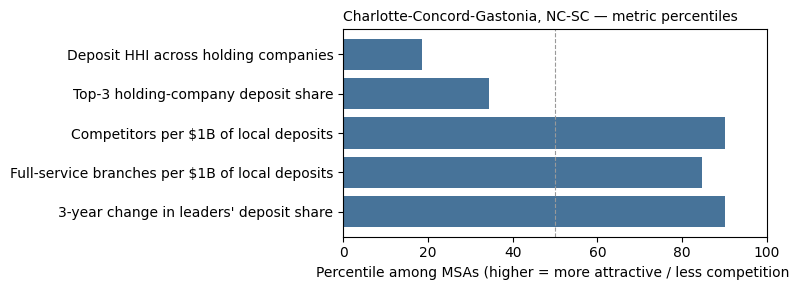

,metric,raw value,percentile,weight,points
deposit_hhi,Deposit HHI across holding companies,"1,975",18.6000,20.0%,3.7200
top3_share,Top-3 holding-company deposit share,61.58%,34.4000,20.0%,6.8900
competitors_per_billion,Competitors per $1B of local deposits,0.68,90.1000,20.0%,18.0100
branches_per_billion,Full-service branches per $1B of local deposits,6.67,84.7000,20.0%,16.9400
leader_share_change,3-year change in leaders' deposit share,-11.14%,90.2000,20.0%,18.0400


In [12]:
ex = EXAMPLE_CBSA
breakdown = pd.DataFrame({
    "metric": REGISTRY.loc[ACTIVE, "label"],
    "raw value": [FORMAT[k](metrics.loc[ex, k]) for k in ACTIVE],
    "percentile": P.loc[ex, ACTIVE].round(1),
    "weight": [f"{EFFECTIVE[k]:.1%}" for k in ACTIVE],
    "points": contrib.loc[ex, ACTIVE].round(2),
})
print(
    f"{TITLE[ex]}: complete score {results.loc[ex, 'complete_score']:.2f}, "
    f"rank {results.loc[ex, 'rank']:.0f} of {int(results['rank'].notna().sum())}"
)
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(ACTIVE) + 1))
    b = breakdown.iloc[::-1]
    ax.barh(b["metric"], b["percentile"], color="#477399")
    ax.axvline(50, color="#999", lw=0.8, ls="--")
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentile among MSAs (higher = more attractive / less competition)")
    ax.set_title(f"{TITLE[ex]} — metric percentiles", loc="left", fontsize=10)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib not installed; table only.")
breakdown


## 8. HQ-booking sensitivity and diagnostics

Rescore with main-office and home-banking bookings kept in, then check metric correlation and weight sensitivity.


In [13]:
long_raw = p3.compute_all(tables, hq_adjusted=False)
wide_raw = p3.to_wide(long_raw)
snap_raw = wide_raw[wide_raw["year"] == SETTINGS["score_year"]].set_index("cbsa_code").reindex(CBSAS)
raw = pd.DataFrame({key: snap_raw[METRIC_ID[key]] for key in ACTIVE}, index=CBSAS)
raw_results, _, _ = score(raw[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict())
cmp_ = results[["msa", "complete_score", "rank"]].join(
    raw_results[["complete_score", "rank"]], rsuffix="_raw"
)
cmp_["score_change"] = cmp_.complete_score - cmp_.complete_score_raw
moved = cmp_[cmp_.score_change.abs() > 10]
print(f"{len(moved)} MSAs move more than 10 points when HQ bookings are kept in.")
cmp_.reindex(cmp_.score_change.abs().sort_values(ascending=False).index).head(12).round(2)


61 MSAs move more than 10 points when HQ bookings are kept in.


,msa,complete_score,rank,complete_score_raw,rank_raw,score_change
41620,"Salt Lake City-Murray, UT",40.5700,275.0000,83.0800,3.0000,-42.5100
39580,"Raleigh-Cary, NC",74.3000,25.0000,40.2600,276.0000,34.0500
37980,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",83.5000,3.0000,51.5400,173.0000,31.9600
48540,"Wheeling, WV-OH",56.4800,139.0000,33.2900,320.0000,23.1900
49420,"Yakima, WA",56.9500,129.0000,34.0400,318.0000,22.9100
29820,"Las Vegas-Henderson-North Las Vegas, NV",51.8500,188.0000,74.6800,30.0000,-22.8300
41700,"San Antonio-New Braunfels, TX",69.8400,46.0000,47.5800,214.0000,22.2600
17410,"Cleveland, OH",66.9200,62.0000,44.9500,239.0000,21.9700
36420,"Oklahoma City, OK",60.3400,109.0000,81.5700,7.0000,-21.2300
48900,"Wilmington, NC",63.1800,86.0000,42.2600,264.0000,20.9100


In [14]:
corr = metrics[ACTIVE].corr(method="spearman").round(2)
high = [
    (a, b, corr.loc[a, b])
    for i, a in enumerate(ACTIVE)
    for b in ACTIVE[i + 1 :]
    if abs(corr.loc[a, b]) >= 0.8
]
print("Highly correlated pairs (|rho| >= 0.8):", high or "none")
corr


Highly correlated pairs (|rho| >= 0.8): [('deposit_hhi', 'top3_share', np.float64(0.97)), ('competitors_per_billion', 'branches_per_billion', np.float64(0.8))]


,deposit_hhi,top3_share,competitors_per_billion,branches_per_billion,leader_share_change
deposit_hhi,1.0000,0.9700,-0.0700,-0.1900,0.1900
top3_share,0.9700,1.0000,-0.1100,-0.2100,0.2000
competitors_per_billion,-0.0700,-0.1100,1.0000,0.8000,-0.0800
branches_per_billion,-0.1900,-0.2100,0.8000,1.0000,-0.0400
leader_share_change,0.1900,0.2000,-0.0800,-0.0400,1.0000


In [15]:
rr = weight_rank_ranges(metrics[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict(), shock=0.25)
top = results.sort_values("rank").head(25).join(rr)
top[["msa", "complete_score", "rank", "best_rank", "worst_rank"]].round(2)


,msa,complete_score,rank,best_rank,worst_rank
35840,"North Port-Bradenton-Sarasota, FL",85.5200,1.0000,1.0000,1.0000
34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",84.3700,2.0000,2.0000,3.0000
37980,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",83.5000,3.0000,2.0000,4.0000
33700,"Modesto, CA",81.9700,4.0000,3.0000,8.0000
26900,"Indianapolis-Carmel-Greenwood, IN",81.6900,5.0000,4.0000,6.0000
38860,"Portland-South Portland, ME",81.5900,6.0000,4.0000,6.0000
28880,"Kiryas Joel-Poughkeepsie-Newburgh, NY",80.3000,7.0000,7.0000,11.0000
34820,"Myrtle Beach-Conway-North Myrtle Beach, SC",79.9500,8.0000,7.0000,14.0000
34940,"Naples-Marco Island, FL",79.8200,9.0000,7.0000,13.0000
45300,"Tampa-St. Petersburg-Clearwater, FL",79.7500,10.0000,8.0000,12.0000


## 9. Export


In [16]:
out_dir = ROOT / "outputs" / "pillar_scores"
out_dir.mkdir(parents=True, exist_ok=True)
table = (
    results.join(metrics[ACTIVE].add_prefix("raw_"))
    .join(P[ACTIVE].add_prefix("pct_"))
    .sort_values(["complete_score", "available_score"], ascending=False)
)
table.rename_axis("cbsa_code").to_csv(out_dir / f"{PILLAR_TAG}_scores.csv")
run = {
    "pillar": PILLAR_TAG,
    "run_date": str(pd.Timestamp.today().date()),
    "effective_weights": EFFECTIVE.round(6).to_dict(),
    "entered_weights": {k: float(v) for k, v in WEIGHTS.items()},
    "settings": SETTINGS,
    "complete_msas": int(results["rank"].notna().sum()),
    "metric_ids": METRIC_ID,
    "not_available": REGISTRY.index[REGISTRY.status == "not available"].tolist(),
}
(out_dir / f"{PILLAR_TAG}_run.json").write_text(json.dumps(run, indent=2, default=str))
print(
    "wrote",
    (out_dir / f"{PILLAR_TAG}_scores.csv").relative_to(ROOT),
    "and",
    (out_dir / f"{PILLAR_TAG}_run.json").relative_to(ROOT),
)


wrote outputs/pillar_scores/pillar3_scores.csv and outputs/pillar_scores/pillar3_run.json


## Note
- **Edit weights in section 2**, then Run All. No YAML edit required for this notebook.
- **HQ adjustment** removes main/home-banking office deposits (fixes Charlotte BofA books; can understate a small HQ metro).
- **P3-05 peer-set share** is not used (removed from Pillar 3).
- **Connecticut** can be partial on P3-07 (missing 3-year base).
- **CRA / metro NIB** are out of Pillar 3 by design.
- For the packaged Excel + point-in-time, see `pillar3_competition_entry_windows.ipynb`.
